# Univariate analysis

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import seaborn as sns
from src.data.loader import load_phenotypes
from src.config import MORE_EXPRESSED_GENES, L1_REGULATORS, L1_REGULATORS_WITH_2_STEPS_FROM_MECP2
from src.data.loader import load_all_regions
import pandas as pd


In [2]:
df = load_phenotypes()

In [3]:
df.head(10)

,SUBJID,SEX,AGE,DTHHRDY
0,GTEX-1117F,2,60-69,4.0
1,GTEX-111CU,1,50-59,0.0
2,GTEX-111FC,1,60-69,1.0
3,GTEX-111VG,1,60-69,3.0
4,GTEX-111YS,1,60-69,0.0
5,GTEX-1122O,2,60-69,0.0
6,GTEX-1128S,2,60-69,2.0
7,GTEX-113IC,1,60-69,NaN
8,GTEX-113JC,2,50-59,2.0
9,GTEX-117XS,1,60-69,2.0


In [4]:
df.describe()

,SEX,DTHHRDY
count,981.000000,962.000000
mean,1.333333,1.209979
std,0.471645,1.448234
min,1.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,2.000000
max,2.000000,4.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SUBJID   981 non-null    str    
 1   SEX      981 non-null    int64  
 2   AGE      981 non-null    str    
 3   DTHHRDY  962 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 30.8 KB


In [6]:
df["SEX"].value_counts()

SEX
1    654
2    327
Name: count, dtype: int64

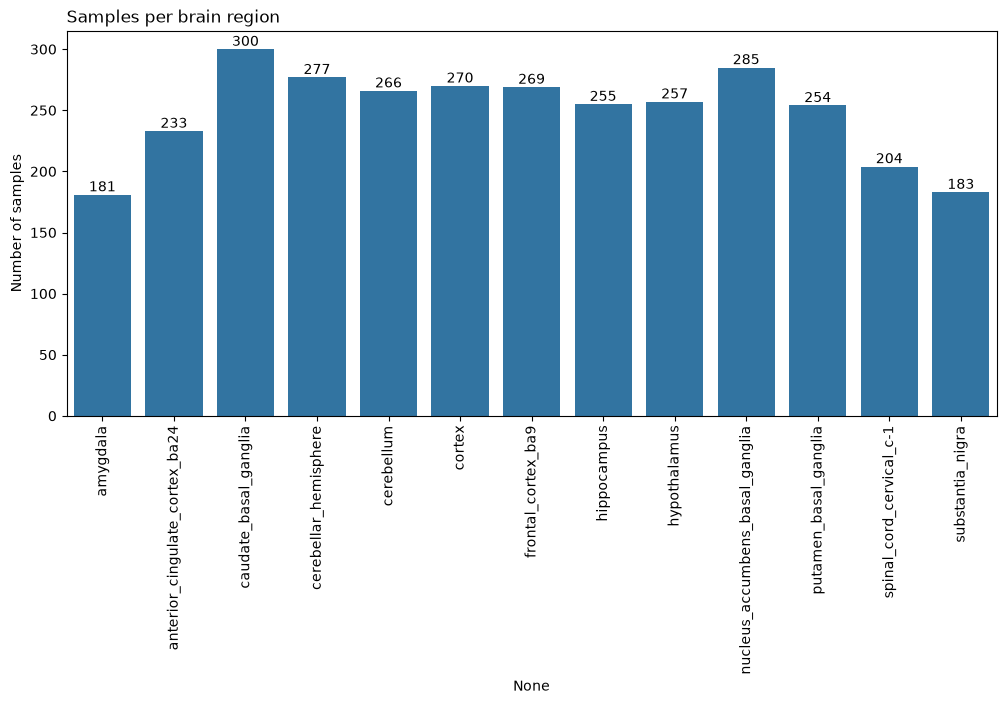

In [7]:

samples_per_region = pd.Series({region.value: len(expr.columns) - 2 for region, expr in load_all_regions(nrows=0).items()})

plt.figure(figsize=(12, 5))
ax = sns.barplot(x=samples_per_region.index, y=samples_per_region.values)
ax.bar_label(ax.containers[0])
plt.xticks(rotation=90)
plt.ylabel("Number of samples")
plt.title("Samples per brain region", loc="left")
plt.show()

Podemos ver que os dados estao distribuidos entre as diferentes regiões do cerebro onde a maior variedade é com a amigdala e o caudado, com 1,7 vezes a diferença.

<Axes: xlabel='SEX', ylabel='count'>

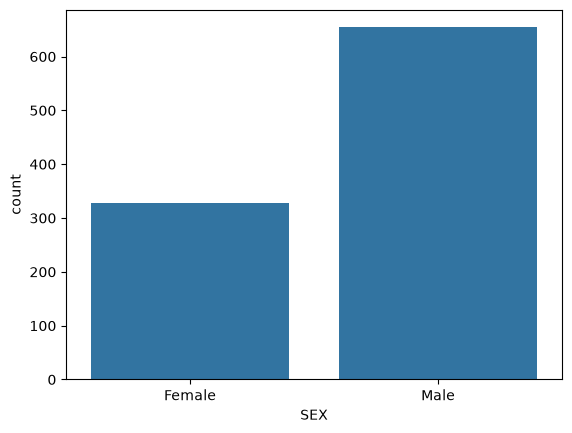

In [8]:
sns.countplot(x=df["SEX"].replace({1: "Male", 2: "Female"}))

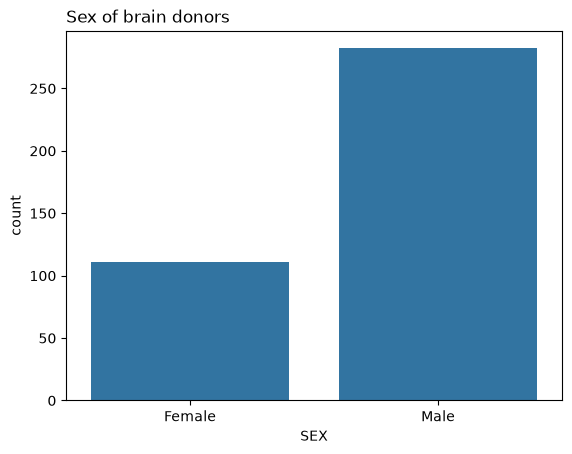

SEX
1    282
2    111
Name: count, dtype: int64

In [9]:
brain_donors = {
    "-".join(sample.split("-")[:2])
    for expr in load_all_regions(nrows=0).values()
    for sample in expr.columns[2:]
}
brain_df = df[df["SUBJID"].isin(brain_donors)]

sns.countplot(x=brain_df["SEX"].replace({1: "Male", 2: "Female"}))
plt.title("Sex of brain donors", loc="left")
plt.show()
brain_df["SEX"].value_counts()

Temos mais que o dobro de amostras vindas de pessoas do sexo masculino, tanto para o descritor de todos os tecidos quanto para os tecidos cerebrais.

<Axes: xlabel='AGE', ylabel='count'>

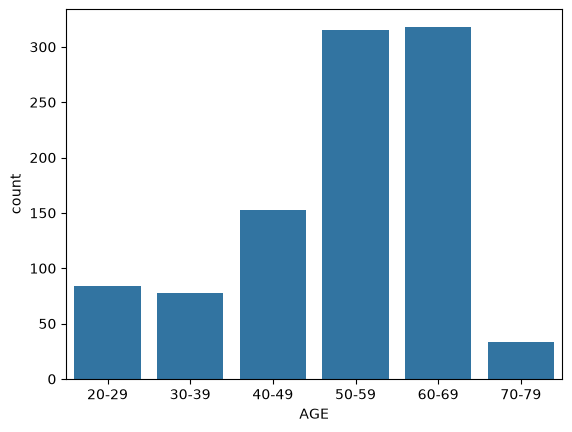

In [10]:
sns.countplot(x=df["AGE"], order=sorted(df["AGE"].unique()))

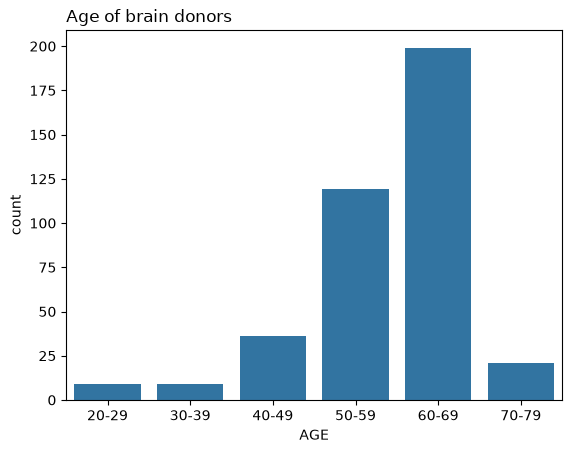

In [11]:
sns.countplot(x=brain_df["AGE"], order=sorted(df["AGE"].unique()))
plt.title("Age of brain donors", loc="left")
plt.show()

Fator importante para a análise os dados que temos se concentra principalmente na faixa etária que é entre 60 - 69 anos. Importante saber disso, pois queremos visualizar como os genes em sexos diferentes variam de expressão ao longo da vida.

<Axes: xlabel='count', ylabel='DTHHRDY'>

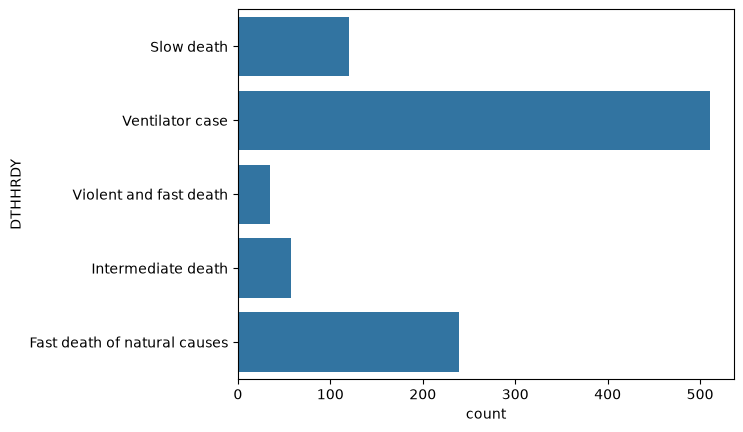

In [12]:
sns.countplot(y=df["DTHHRDY"].replace({
    0 : "Ventilator case",
    1 : "Violent and fast death",
    2: "Fast death of natural causes",
    3 : "Intermediate death",
    4: "Slow death"
}))

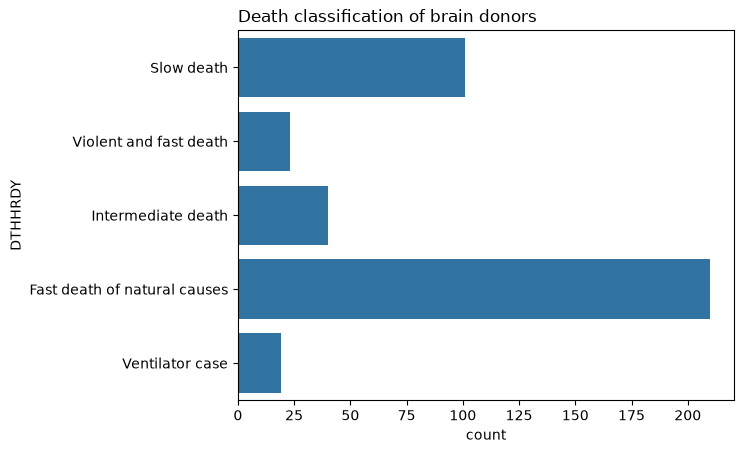

In [13]:
sns.countplot(y=brain_df["DTHHRDY"].replace({
    0 : "Ventilator case",
    1 : "Violent and fast death",
    2: "Fast death of natural causes",
    3 : "Intermediate death",
    4: "Slow death"
}))
plt.title("Death classification of brain donors", loc="left")
plt.show()

Uma grande limitação que temos é um contraste muito grande entre os tipos de causas de morte. Melhores descritos em `src/data/README.md`

In [14]:
regions = load_all_regions(nrows=None)

In [15]:
genes = []
for region, expr in regions.items():
    g = expr[expr["Description"].isin(L1_REGULATORS + MORE_EXPRESSED_GENES)]
    g = g.drop(columns="Name").melt(id_vars="Description", var_name="sample", value_name="TPM")
    g["region"] = region.value
    genes.append(g)

genes = pd.concat(genes)
print(genes.shape)
genes.head()

(352506, 4)


,Description,sample,TPM,region
0,KDM1A,GTEX-1117F-0011-R4b-SM-GI4VM,8.842710,amygdala
1,RUNX3,GTEX-1117F-0011-R4b-SM-GI4VM,0.967832,amygdala
2,PABPC4,GTEX-1117F-0011-R4b-SM-GI4VM,24.448600,amygdala
3,TUT4,GTEX-1117F-0011-R4b-SM-GI4VM,5.511600,amygdala
4,HENMT1,GTEX-1117F-0011-R4b-SM-GI4VM,3.591080,amygdala


In [16]:
expression = pd.concat(
    [expr.set_index(["Name", "Description"]) for expr in regions.values()], axis=1
)
expression.shape

(74628, 3234)

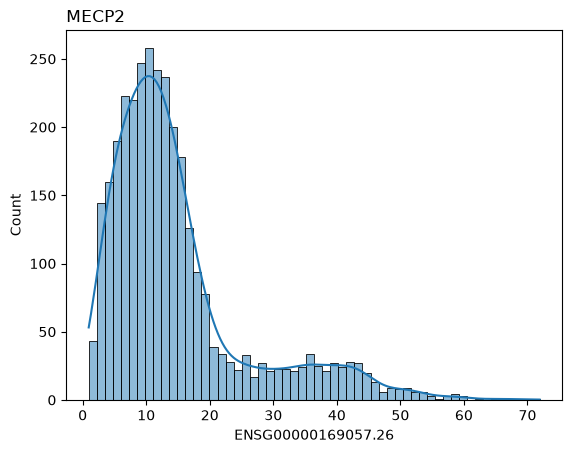

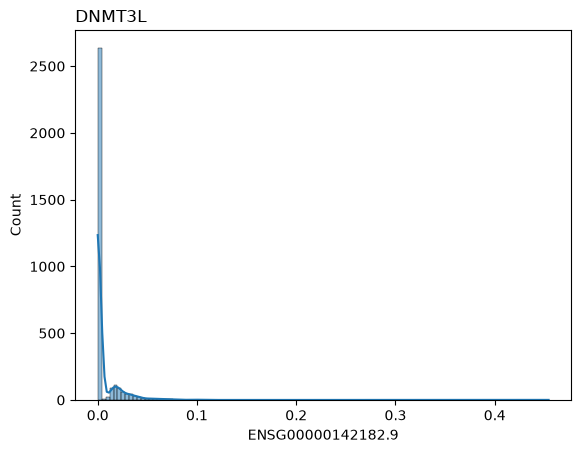

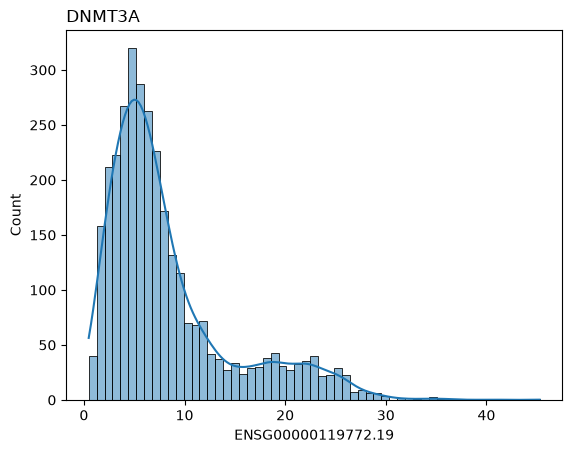

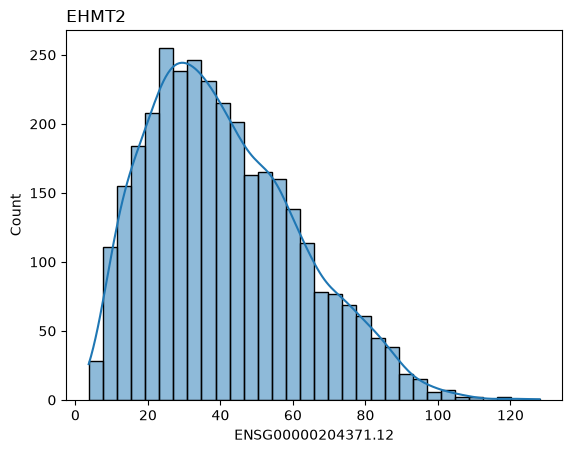

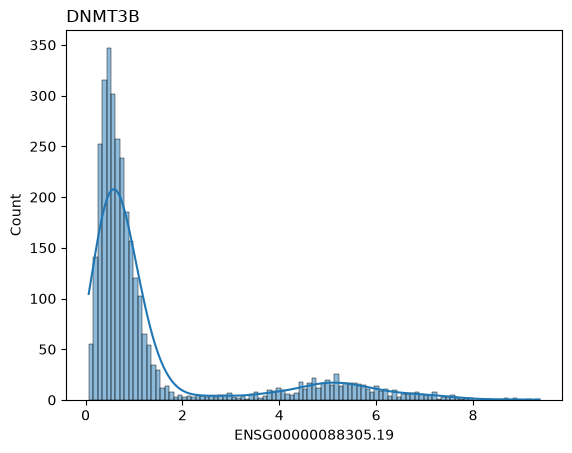

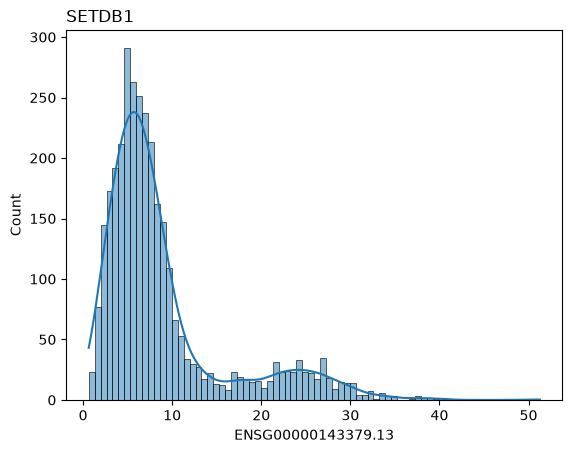

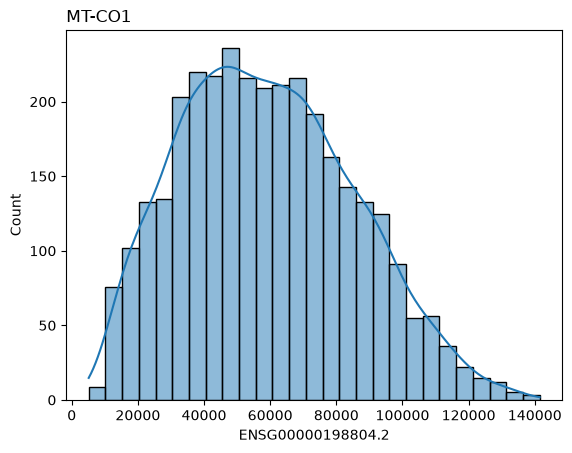

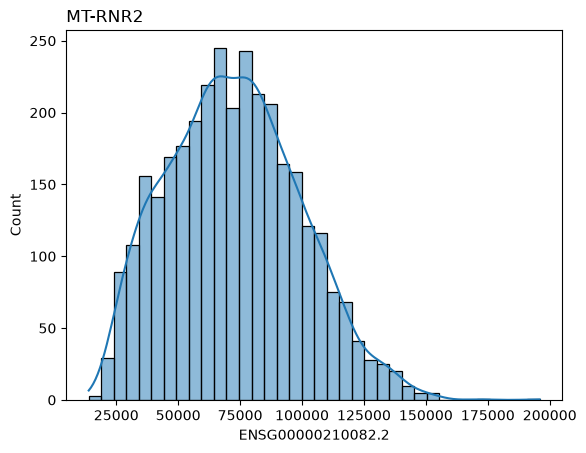

In [17]:
for gene in L1_REGULATORS_WITH_2_STEPS_FROM_MECP2 + MORE_EXPRESSED_GENES:
    tpm = expression.xs(gene, level="Description").iloc[0]
    sns.histplot(tpm, kde=True)
    plt.title(gene, loc="left")
    plt.show()

Esses genes foram selecionados por conheciamento de dominio, L1 derivado de pesquisas em RETT e os MT-* por serem os genes que apresentaram maior variancia nas análises multivariadas.

In [18]:
l1 = genes[genes["Description"].isin(L1_REGULATORS)]

l1_variation = l1.groupby("Description")["TPM"].agg(["mean", "std", "var", "median", "min","max"])
l1_variation = l1_variation.sort_values("var", ascending=False)
pd.set_option("display.max_rows", None)
l1_variation

,mean,std,var,median,min,max
Description,,,,,,
HSP90AA1,699.556733,648.457224,420496.771741,586.258500,50.301900,11038.900000
PABPN1,166.528361,101.949531,10393.706926,140.165000,13.837100,626.100000
HNRNPA2B1,139.159864,88.162079,7772.552110,114.512000,12.541700,572.068000
MATR3,123.531390,74.001400,5476.207229,108.693000,8.347910,511.379000
HNRNPL,106.704864,60.047510,3605.703460,94.197950,9.803010,397.647000
NCL,110.932614,54.372767,2956.397842,99.932550,12.974200,365.579000
XRCC6,100.042270,52.229826,2727.954733,92.680150,10.167900,317.946000
TRIM28,69.347144,49.966039,2496.605043,54.293700,6.497580,326.587000
UPF3A,51.561666,38.149064,1455.351081,38.059350,4.549770,196.008000


Tabela para ver o quanto os valores dos reguladores variam entre si

## Variáveis por amostra

In [19]:
sample_features = []
for region, expr in regions.items():
    tpm = expr.drop(columns=["Name", "Description"])
    gene_names = expr["Description"]
    l1_tpm = tpm[gene_names.isin(L1_REGULATORS)]
    sample_features.append(pd.DataFrame({
        "region": region.value,
        "genes_detected": (tpm > 0).sum(),
        "mito_fraction": tpm[gene_names.str.startswith("MT-")].sum() / tpm.sum(),
        "l1_mean": l1_tpm.mean(),
        "l1_median": l1_tpm.median(),
        "l1_std": l1_tpm.std(),
    }))

sample_features = pd.concat(sample_features)
sample_features.index.name = "sample"
sample_features["SUBJID"] = sample_features.index.str.split("-").str[:2].str.join("-")
sample_features["regions_per_donor"] = sample_features.groupby("SUBJID")["region"].transform("count")
sample_features.head()

,region,genes_detected,mito_fraction,l1_mean,l1_median,l1_std,SUBJID,regions_per_donor
sample,,,,,,,,
GTEX-1117F-0011-R4b-SM-GI4VM,amygdala,35046,0.740931,14.165109,4.11165,28.287962,GTEX-1117F,9
GTEX-111FC-0011-R4a-SM-GIN8K,amygdala,35142,0.587657,22.240392,4.95087,61.893634,GTEX-111FC,11
GTEX-117XS-0011-R4b-SM-GJ3PR,amygdala,35328,0.614051,21.408056,5.43052,59.581817,GTEX-117XS,13
GTEX-11DXY-0011-R4b-SM-GI4VR,amygdala,37243,0.524980,24.858480,7.14566,59.710646,GTEX-11DXY,11
GTEX-11DYG-0011-R4b-SM-GJ3RG,amygdala,32464,0.681308,12.833903,3.34781,30.325916,GTEX-11DYG,10


In [23]:
numeric_features = ["genes_detected", "mito_fraction", "l1_mean", "l1_median", "l1_std", "regions_per_donor"]
pd.concat([sample_features[numeric_features].describe(), sample_features[numeric_features].agg(["skew", "kurt"])])

,genes_detected,mito_fraction,l1_mean,l1_median,l1_std,regions_per_donor
count,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000,3234.000000
mean,36176.974026,0.592753,26.083219,6.653384,75.150758,9.651206
std,2625.751159,0.151567,13.644341,3.107452,62.566485,2.578106
min,24483.000000,0.106651,3.036241,0.667770,6.108473,1.000000
25%,34704.000000,0.491007,16.850203,4.416120,42.614337,8.000000
50%,36344.500000,0.593865,23.812030,6.181195,65.739133,10.000000
75%,37896.000000,0.702225,32.819737,8.422557,89.926798,12.000000
max,51854.000000,0.935189,140.888908,21.483600,1065.398804,13.000000
skew,-0.294930,-0.149304,1.710981,0.774291,6.364895,-1.024492
kurt,1.169014,-0.544470,7.438123,0.611537,69.214402,0.608591


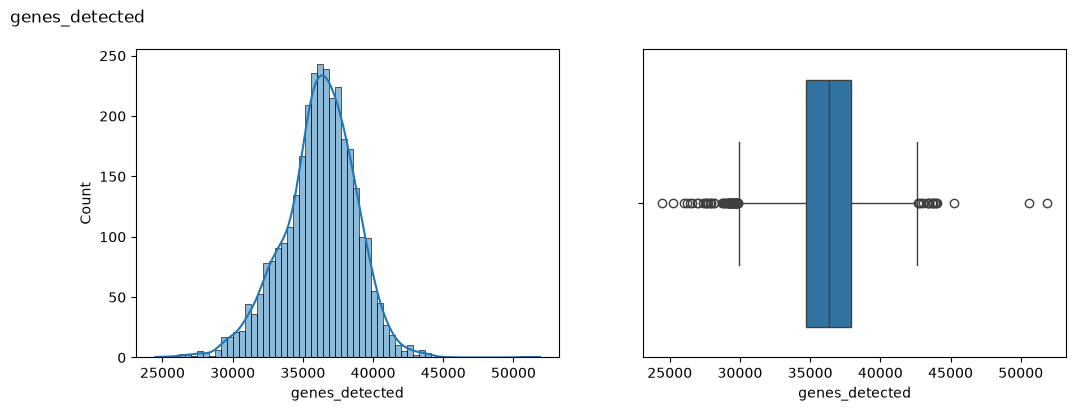

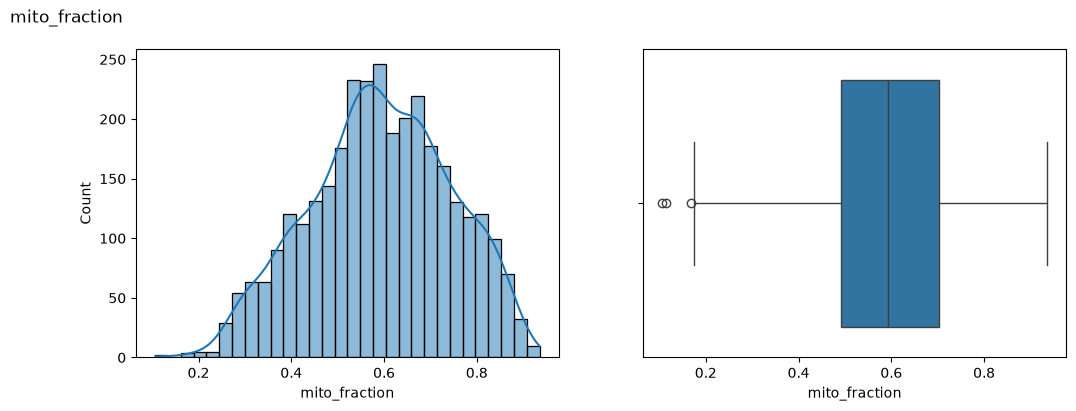

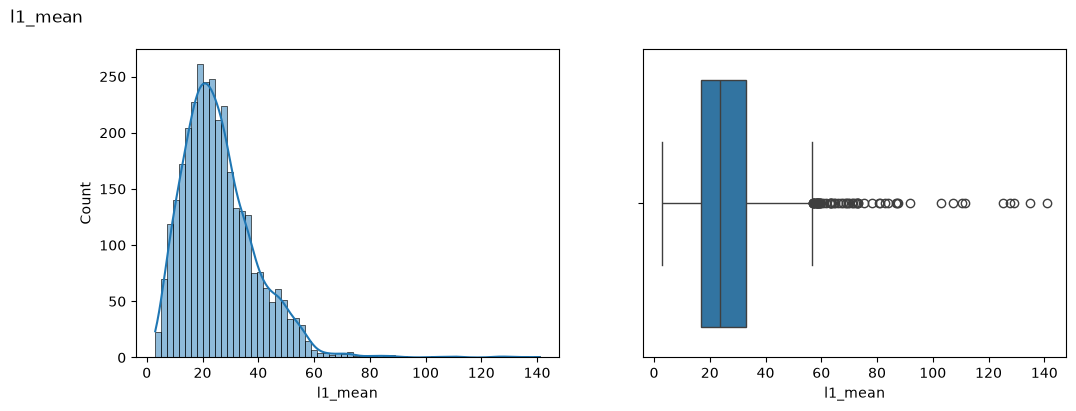

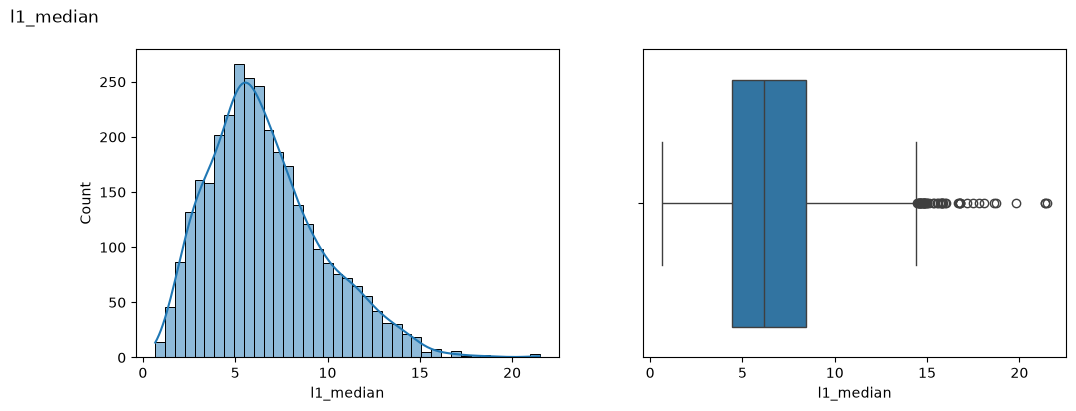

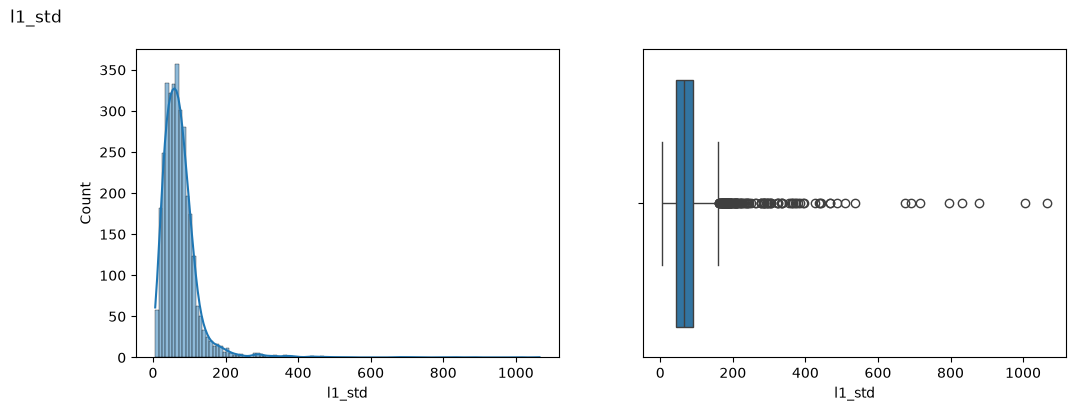

In [21]:
for feature in ["genes_detected", "mito_fraction", "l1_mean", "l1_median", "l1_std"]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(sample_features[feature], kde=True, ax=axes[0])
    sns.boxplot(x=sample_features[feature], orient="h", ax=axes[1])
    fig.suptitle(feature, x=0.02, ha="left")
    plt.show()

As variáveis ligadas ao painel de reguladores de L1 têm assimetria positiva: `l1_mean` (skew 1,71), `l1_median` (0,77) e principalmente `l1_std` (6,37). Já `genes_detected` (-0,30) e `mito_fraction` (-0,15) são praticamente simétricas.

A média de `l1_mean` (26,1 TPM) fica bem acima da mediana do painel (6,7 TPM), o que mostra que poucos genes muito expressos puxam a média para cima. O `l1_std` tem curtose de 69, ou seja, há poucas amostras com valores muito extremos, que aparecem como outliers no boxplot.

Por isso as variáveis do painel de L1 precisam de uma transformação para ficarem mais simétricas, por exemplo log, antes de serem usadas em modelos que desempenham melhor com esse tipo de distribuição.

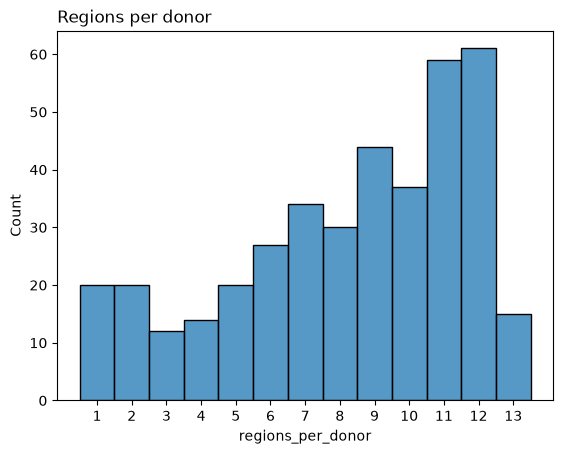

In [22]:
donors = sample_features.drop_duplicates("SUBJID")
sns.histplot(donors["regions_per_donor"], discrete=True)
plt.xticks(range(1, 14))
plt.title("Regions per donor", loc="left")
plt.show()

Aqui vemos que poucos doadores aparecem em apenas uma região: são 20 dos 393 doadores (5%). A maior parte doou amostras de 9 ou mais regiões, e 15 doadores têm as 13 regiões. Assim, é possível comparar como os genes variam em diferentes conjuntos anatômicos dentro da mesma pessoa.